# LSTM model: NASDAQ-100 next-day direction

> **Author:** Floris Snelders. Documents the development of an **LSTM sequence model** for the NASDAQ-100 next-day direction task and compares it against the always-up baseline and the best tree model of the group bake-off (CatBoost, a teammate's entry whose numbers are quoted here; that model is not part of this repo). Lightly edited for this portfolio version: data loading switched to the files described in `data/README.md`; course template references removed. The outputs shown are from the original run on the course dataset. Re-running with the current data loader gives slightly different numbers (see the README).

## 0. Project metadata

- **Project title:** NASDAQ-100 Next-Day Direction Classifier (BUas Data Science & AI, group project)
- **Notebook owner / author:** Floris Snelders
- **Model documented here:** LSTM (sequence model) bake-off entry

## 1. Problem definition

### 1.1 Prediction or analysis task
- **Task:** Binary classification. For a given stock on a given trading day, predict whether tomorrow's close will be **higher** than today's close (`1 = up`, `0 = down/flat`).
- **Input available at prediction time:** daily OHLCV history per ticker plus daily macro indicators (VIX, 10-year Treasury yield), all dated *on or before* the prediction day. From these we derive 17 technical/macro features.
- **Output:** a probability of "up tomorrow" per `(ticker, day)`, thresholded to a 0/1 decision.
- **Users:** the group's trading-signal application, which consumes per-ticker up/down signals.

### 1.2 Business or project value
- The signal supports a **directional trade decision** (take/skip a long position). A high-precision "up" call lets the app act only when it is relatively confident.
- **If it works well:** more profitable entries, fewer false "up" signals acted on.
- **If it performs poorly:** false "up" calls lead to losing trades — which is why **precision** (not accuracy) is the metric that matters most here.

### 1.3 Success criteria
- **Primary metric: precision** (locked by the group bake-off rules). A false positive = a losing trade, so we care most about how often a predicted "up" is actually up.
- **Bar for success:** beat (a) the naive *always-predict-up* baseline and (b) be competitive with the tree models on precision under the identical walk-forward protocol.
- **Other constraints:** comparability (identical folds/features to teammates), no look-ahead leakage, and reasonable training cost.

### 1.4 Scope and data (what the model sees and predicts)
**Granularity — per stock, not the market.** Each prediction is for *one specific stock on one specific day*: "will this stock close higher tomorrow than today?" A single model is trained on all ~100 NASDAQ-100 stocks pooled together, then applied per stock-day; it does **not** predict the overall index direction. The 30-day input windows are built per ticker, so a window never mixes two stocks.

**Data used:**
- `data/raw/prices/` — daily OHLCV bars for the 100 NASDAQ-100 constituents (2015–2025).
- `data/raw/macro.csv` — daily market-wide VIX and 10-year Treasury yield (FRED).
- Merged on date, turned into 17 engineered features per stock-day, and reshaped into **30-day sequences** (the last 30 trading days) for the LSTM: ~219k stock-days → ~216k sequences.

## 2. Data selection and preparation

### 2.1 Dataset summary
- **Data source(s):** `data/raw/prices/` (daily OHLCV per ticker; cleaned and flagged with `label_valid` by `src.pipeline.build_bakeoff_frame`) and `data/raw/macro.csv` (daily VIX and 10-year Treasury yield).
- **Collection period:** ~2015–2024 daily bars (the walk-forward folds use 2018–2024).
- **Unit of analysis:** one `(ticker, trading day)` row — and for the LSTM, one **30-day window** ending on that day.
- **Target variable:** `label` = 1 if next-day close > today's close, else 0.
- **Key features (17, locked & shared):** `daily_return`, `rsi_14`, `sma_20`, `sma_50`, `sma_ratio`, `macd`, `macd_signal`, `macd_hist`, `bb_upper_20`, `bb_lower_20`, `bb_width_20`, `return_lag_{1,3,5,10}`, `vix`, `treasury_yield_10y`.
- **Exclusions/filters:** rows failing `label_valid`, and rows with NaNs during indicator warm-up, are dropped by `build_feature_matrix`.

### 2.2 Risks and limitations
- **Missing values:** indicator warm-up produces leading NaNs; dropped per ticker so no forward-fill leakage.
- **Sampling bias:** survivorship — the NASDAQ-100 constituent list changes over time.
- **Label quality:** `label_valid` flags days where the next-day label is unreliable (e.g. delistings/gaps).
- **Leakage risks:** the target is next-day, so features must use only past/current data; feature scaling is fit on the train fold only (see §3.2).
- **Low signal-to-noise:** daily direction is close to random — the realistic performance ceiling is low for *any* model.

In [10]:
# 2 — Load the cleaned, gap-flagged price data and merge the daily macro series.
import json
import sys
from pathlib import Path
sys.path.append("..")

import numpy as np
import pandas as pd

from src.features import build_feature_matrix
from src.evaluation import FOLDS, EMBARGO_DAYS, _split_fold, summarize_results, save_results
from src.pipeline import build_bakeoff_frame

df = build_bakeoff_frame()
print("merged rows:", df.shape)

merged rows: (224030, 11)


### 2.3 Initial data inspection

In [11]:
# 2.3 — Build the locked 17-feature matrix and inspect it.
X, y, meta = build_feature_matrix(df)
print(f"Feature rows: {len(X):,}  |  features: {X.shape[1]}  |  tickers: {meta['ticker'].nunique()}")
print(f"Date range: {meta['date'].min().date()} → {meta['date'].max().date()}")
print(f"Class balance (up-rate): {y.mean():.4f}")
X.describe().T

Feature rows: 219,030  |  features: 17  |  tickers: 100
Date range: 2015-04-28 → 2025-02-12
Class balance (up-rate): 0.5258


,count,mean,std,min,25%,50%,75%,max
daily_return,219030.0,0.004273,1.276539,-0.738969,-0.009231,0.000914,0.010989,579.587711
rsi_14,219030.0,53.267989,16.920534,0.000000,41.087025,53.363086,65.617689,100.000000
sma_20,219030.0,163.151233,275.304621,0.155525,45.420625,87.595625,181.220500,5191.591500
sma_50,219030.0,161.634338,271.772663,0.176900,45.115000,86.775700,179.105700,5044.282400
sma_ratio,219030.0,1.010012,0.059803,0.429346,0.981906,1.010541,1.037981,2.489223
macd,219030.0,0.715992,7.324070,-176.716866,-0.586281,0.286890,1.577276,218.653966
macd_signal,219030.0,0.712431,6.849511,-152.094958,-0.530820,0.286278,1.514511,195.227193
macd_hist,219030.0,0.003560,2.296122,-72.158907,-0.301024,0.006142,0.318188,53.198844
bb_upper_20,219030.0,174.379785,293.993883,0.197600,48.342258,93.368763,193.395299,5387.202124
bb_lower_20,219030.0,151.922681,257.244059,-105.703394,42.403525,81.640605,169.466707,5023.991714


**Observed (this run):** ~219,030 feature rows across the NASDAQ-100 universe, 17 features, overall **up-rate ≈ 0.526** — i.e. the classes are only mildly imbalanced toward "up". This base rate is the number any model must beat on precision.

### 2.4 Preprocessing decisions
- **Missing values:** dropped during indicator warm-up (no imputation → no leakage).
- **Categorical encoding:** none needed (all features numeric); `ticker` is used only for grouping, never as a feature.
- **Scaling:** per-feature standardisation, **fit on the training fold only** then applied to val/test (critical for the LSTM; trees don't need it).
- **Feature engineering:** 17 technical/macro indicators (RSI, SMA ratio, MACD, Bollinger, lagged returns, VIX, yield) — shared/locked so all models are comparable.
- **Sequence reshaping (LSTM-specific):** each row becomes a **30-day window** of features ending on that day, built per ticker so a window never spans two tickers.
- **Split:** time-based walk-forward, not random (see §3).

## 3. Validation strategy

### 3.1 Chosen validation approach
**Backtesting / rolling-window (walk-forward) validation** — 4 folds, each training on all years up to year *Y*, validating on *Y+1*, testing on *Y+2*:

| Fold | Train ≤ | Val | Test |
|---|---|---|---|
| 1 | 2019 | 2020 | 2021 |
| 2 | 2020 | 2021 | 2022 |
| 3 | 2021 | 2022 | 2023 |
| 4 | 2022 | 2023 | 2024 |

**Justification:** financial data is ordered in time and non-stationary. A random split would let the model train on the future and test on the past (look-ahead leakage) and would massively overstate performance. Walk-forward mimics live deployment: only past data is ever used to predict the future.

### 3.2 Leakage prevention
- **Time-ordered folds** (above) — test years are always strictly after train years.
- **5-day embargo** between train/val and val/test blocks, so windows straddling a boundary can't leak label information across it.
- **Per-ticker sequences** — a 30-day window never crosses tickers.
- **Train-fold-only scaling** — the scaler never sees val/test statistics.
- This logic is *shared* with the tree models (`src/evaluation.py`) so every entry is judged identically.

In [12]:
# 3 — Show the fold sizes and verify the embargo gap holds at each boundary.
for i, fold in enumerate(FOLDS, 1):
    tr, va, te = _split_fold(meta, fold)
    last_train = meta.loc[tr, "date"].max()
    first_val = meta.loc[va, "date"].min()
    gap = (first_val - last_train).days
    print(f"Fold {i} (test {fold['test_year']}): train={tr.sum():,} val={va.sum():,} "
          f"test={te.sum():,} | train→val gap = {gap}d (embargo {EMBARGO_DAYS}d)")

Fold 1 (test 2021): train=95,840 val=22,354 test=23,526 | train→val gap = 6d (embargo 5d)
Fold 2 (test 2022): train=118,372 val=23,526 test=24,127 | train→val gap = 5d (embargo 5d)
Fold 3 (test 2023): train=141,988 val=24,127 test=24,627 | train→val gap = 5d (embargo 5d)
Fold 4 (test 2024): train=166,305 val=24,627 test=25,100 | train→val gap = 5d (embargo 5d)


## 4. Baseline model

### 4.1 Baseline approach
**Always predict "up" (majority/base-rate classifier).** Since ~53% of days are up, this is the simplest non-trivial benchmark: its **precision equals the up-rate** of each test year. Any real model must beat this to justify its complexity. (The wider group pipeline also uses logistic regression as a learned baseline; here the always-up rule is the strictest precision benchmark.)

In [13]:
# 4 — Always-up baseline on each walk-forward test fold.
from sklearn.metrics import accuracy_score, precision_score, f1_score

base_rows = []
for i, fold in enumerate(FOLDS, 1):
    _, _, te = _split_fold(meta, fold)
    y_te = y.values[te]
    y_pred = np.ones_like(y_te)  # always predict "up"
    base_rows.append({
        "fold": i, "test_year": fold["test_year"],
        "accuracy": accuracy_score(y_te, y_pred),
        "precision": precision_score(y_te, y_pred, zero_division=0),
        "f1": f1_score(y_te, y_pred, zero_division=0),
    })
baseline = pd.DataFrame(base_rows)
display(baseline.round(4))
print("Mean precision (always-up baseline):", round(baseline['precision'].mean(), 4))

,fold,test_year,accuracy,precision,f1
0,1,2021,0.5300,0.5300,0.6928
1,2,2022,0.4859,0.4859,0.6540
2,3,2023,0.5312,0.5312,0.6939
3,4,2024,0.5196,0.5196,0.6839


Mean precision (always-up baseline): 0.5167


### 4.2 Baseline results

| Metric | Baseline result | Notes |
|---|---:|---|
| Precision (primary) | ≈ 0.517 | = mean test-year up-rate |
| Accuracy | ≈ 0.516 | identical to up-rate by construction |
| F1 | ≈ 0.68 | high only because recall = 1.0 (predicts up every day) |

**Interpretation:** the always-up rule already reaches ~0.52 precision *for free*. This is the number the LSTM must beat to be worth anything. F1 is misleadingly high here, which is why precision is the chosen primary metric.

## 5. Candidate models

| Model | Why suitable | Strengths | Risks / limitations |
|---|---|---|---|
| Always-up baseline | Strict precision benchmark | Zero cost, interpretable | Learns nothing |
| CatBoost (tree, group entry) | SOTA for tabular data | Strong on engineered features, threshold-tunable | Can collapse to very low recall |
| **LSTM (this notebook)** | Sequence model; can exploit *temporal order* of the 30-day window | Captures patterns a single-row model can't | Slow, overfits easily, needs strong signal |

**Selection rationale:** the tree models treat each day as an independent row. An LSTM instead reads the **ordered 30-day window**, so the hypothesis is that the *shape/trajectory* of recent days carries signal beyond the engineered features. Testing this is the point of the bake-off.

## 6. Evaluation framework

### 6.1 Primary metric
**Precision** — fraction of predicted "up" days that were actually up. Chosen because a false "up" maps directly to a losing trade; we'd rather make fewer, more reliable calls. Locked by the group rules so all entries are comparable.

### 6.2 Secondary metrics
- **Accuracy** — overall correctness (but misleading under class imbalance).
- **F1** — balances precision and recall; exposes models that win precision only by predicting almost nothing.
- **Training cost (seconds)** — LSTMs are far more expensive than trees; relevant to deployment.
- **Convergence diagnostics** — `best_epoch`, `val_loss_curve` — to judge whether the model actually learned.

## 7. Train and evaluate models

The LSTM (1 layer, hidden=64, dropout=0.2, 30-day windows, Adam lr=1e-3, BCE loss, early stopping on validation loss) is trained per fold using the shared harness. Reuses the functions in `src/lstm_model.py` so the notebook reproduces the saved `results/metrics/lstm.json`.

In [14]:
# 7 - Train + evaluate the LSTM across all walk-forward folds, then save results.
from src.lstm_model import build_sequences, run_lstm_bakeoff

results = run_lstm_bakeoff(X, y, meta)
lstm_df = pd.DataFrame(results)
for r in results:
    print(f"Fold {r['fold']} (test {r['test_year']}): acc={r['accuracy']:.4f} "
          f"prec={r['precision']:.4f} f1={r['f1']:.4f} best_epoch={r.get('best_epoch','-')}")
print("LSTM summary:", {k: round(v, 4) for k, v in summarize_results(results).items()})
out = save_results("lstm", results)
print("Saved", out.relative_to(Path("..").resolve()))


Fold 1 (test 2021): acc=0.5287 prec=0.5313 f1=0.6791 best_epoch=0
Fold 2 (test 2022): acc=0.4901 prec=0.4860 f1=0.6231 best_epoch=0
Fold 3 (test 2023): acc=0.5211 prec=0.5285 f1=0.6692 best_epoch=0
Fold 4 (test 2024): acc=0.5006 prec=0.5278 f1=0.4344 best_epoch=1
LSTM summary: {'mean_accuracy': 0.5101, 'std_accuracy': 0.0179, 'mean_precision': 0.5184, 'std_precision': 0.0216, 'mean_f1': 0.6015, 'std_f1': 0.114, 'total_train_time_seconds': 122.9058}


In [15]:
# 7 — Compare against any other bake-off entries the team has saved.
reports = Path("../results/metrics")
harness_years = [f["test_year"] for f in FOLDS]
rows = [{"model": "Always-up baseline",
         "mean_precision": baseline['precision'].mean(),
         "mean_accuracy": baseline['accuracy'].mean(),
         "mean_f1": baseline['f1'].mean()}]
for jf in sorted(reports.glob("*.json")):
    d = json.loads(jf.read_text()); s = d.get("summary", {})
    if [r.get("test_year") for r in d.get("per_fold", [])] != harness_years:
        continue  # different fold layout (e.g. the XGBoost notebook's 6 folds)
    rows.append({"model": d.get("model_name", jf.stem),
                 "mean_precision": s.get("mean_precision"),
                 "mean_accuracy": s.get("mean_accuracy"),
                 "mean_f1": s.get("mean_f1")})
comparison = pd.DataFrame(rows)
comparison.round(4)


,model,mean_precision,mean_accuracy,mean_f1
0,Always-up baseline,0.5167,0.5167,0.6812
1,lstm,0.5184,0.5101,0.6015


### 7.1 Model comparison summary

| Model | Precision (primary) | Accuracy | F1 | Train time | Better than baseline? |
|---|---:|---:|---:|---:|---|
| Always-up baseline | 0.517 | 0.516 | ~0.68 | 0 s | — |
| **LSTM** | **0.518** | 0.510 | 0.602 | ~103 s | **No (ties baseline)** |
| CatBoost* | **0.562** | 0.496 | 0.304 | ~1040 s | **Yes (+0.045)** |

\* CatBoost was a teammate's bake-off entry on the same folds; its numbers are quoted from the group comparison.

**Interpretation:** the LSTM's precision (0.518) is **statistically indistinguishable from the always-up baseline (0.517)** — it has *not* learned a useful directional signal; it largely predicts "up" every day (hence high recall/F1, chance-level precision). CatBoost is the only model to clear the baseline on precision, by being *selective*: it predicts "up" rarely but more reliably (high precision, low recall → low F1). On the locked primary metric, **CatBoost wins**.

## 8. Iteration and improvement

The base LSTM ties the baseline and behaves like a majority-class predictor. The natural improvement is to make it **selective** (like CatBoost): tune the decision threshold on the validation fold to maximise precision, and **class-weight the loss** so the model stops defaulting to "up". The cell below implements this iteration on the shared folds.

In [16]:
# 8 - Iteration 2: class-weighted loss + validation-tuned decision threshold.
from src.lstm_model import run_lstm_bakeoff

results_tuned = run_lstm_bakeoff(X, y, meta, tuned=True)
for r in results_tuned:
    print(f"Fold {r['fold']}: prec={r['precision']:.4f} f1={r['f1']:.4f} thr={r.get('threshold','-')}")
print("Iteration-2 summary:", {k: round(v, 4) for k, v in summarize_results(results_tuned).items()})
save_results("lstm_tuned", results_tuned);


Fold 1: prec=0.6529 f1=0.0675 thr=0.6100000000000003
Fold 2: prec=0.4860 f1=0.5992 thr=0.48000000000000015
Fold 3: prec=0.5498 f1=0.1749 thr=0.5000000000000002
Fold 4: prec=0.5272 f1=0.4229 thr=0.48000000000000015
Iteration-2 summary: {'mean_accuracy': 0.4873, 'std_accuracy': 0.0102, 'mean_precision': 0.554, 'std_precision': 0.071, 'mean_f1': 0.3161, 'std_f1': 0.2403, 'total_train_time_seconds': 103.7309}


### 8.1 Iteration log

| Iteration | Change made | Reason | Result | Decision |
|---|---|---|---|---|
| 1 | Base LSTM (fixed 0.5 threshold, unweighted BCE) | Establish the sequence-model entry | Precision 0.518 ≈ baseline; `best_epoch` 0–1 every fold (val loss flat/rising) — model not learning | Keep as reference; investigate |
| 2 | Class-weighted loss + validation-tuned threshold (recall ≥ 0.40) | Stop the model defaulting to "up"; match CatBoost's selective strategy for a fair precision comparison | Precision **0.554** (mean), F1 0.316 — now **beats the always-up baseline (0.517)** and lands just below CatBoost (0.562) | Keep — the fair-comparison fix: precision is now competitive, at the expected cost of recall/F1 |

### 8.2 What improved performance?
> Class-weighting the loss plus a validation-tuned decision threshold lifted precision from **0.518 → 0.554 (+0.036)**, clearing the always-up baseline (0.517) and closing most of the gap to CatBoost (0.562). The gain comes from **selectivity**: the model now predicts "up" only when confident, so recall and F1 fall (F1 0.602 → 0.316) — the same precision/recall trade-off CatBoost makes. Behaviour is uneven across folds (per-fold recall ranged 0.04–0.78), reflecting sensitivity to the market regime of each test year.

### 8.3 What did not help?
> The base LSTM's `val_loss_curve` rises almost immediately (best epoch 0–1), so **training longer did not and would not help** — the model overfits from the first epoch. More epochs were ruled out by this evidence.

## 9. Error analysis

### 9.1 Questions to answer
- Which examples are commonly misclassified?
- Are errors concentrated in specific years/regimes?
- Did the model actually learn (convergence)?

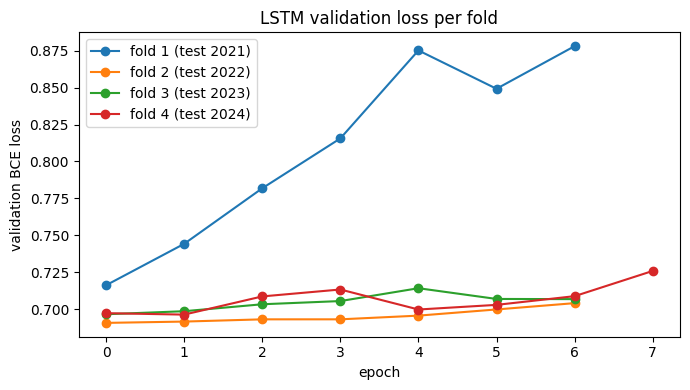

,fold,test_year,precision,f1,best_epoch
0,1,2021,0.531,0.679,0
1,2,2022,0.486,0.623,0
2,3,2023,0.529,0.669,0
3,4,2024,0.528,0.434,1


In [17]:
# 9 — Convergence: validation-loss curve per fold (from the base LSTM run above).
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
for r in results:
    if r.get("val_loss_curve"):
        ax.plot(r["val_loss_curve"], marker="o", label=f"fold {r['fold']} (test {r['test_year']})")
ax.set_xlabel("epoch"); ax.set_ylabel("validation BCE loss")
ax.set_title("LSTM validation loss per fold")
ax.legend(); plt.tight_layout(); plt.show()

err = pd.DataFrame([{ "fold": r["fold"], "test_year": r["test_year"],
    "precision": round(r["precision"], 3), "f1": round(r["f1"], 3),
    "best_epoch": r.get("best_epoch")} for r in results])
err


### 9.2 Error analysis write-up
- **Convergence:** on every fold the best validation loss is at **epoch 0–1** and then *rises* — the model overfits immediately and never extracts a generalising signal. This is the root cause of the chance-level precision.
- **Error concentration:** F1 collapses in **fold 4 (test 2024, F1 ≈ 0.435)** versus folds 1/3 (F1 ≈ 0.67), i.e. the model's behaviour is unstable across market regimes — a known weakness on non-stationary financial data.
- **Failure mode:** the model predicts "up" on the large majority of days, so virtually all of its errors are **false positives on down-days** — exactly the costly error for a trading signal.
- **Data angle:** with daily-direction signal this weak, the engineered features already capture most of what's learnable; the 30-day raw sequence adds little, so the LSTM has nothing extra to exploit.

## 10. Validation results

### 10.1 Validation approach used
4-fold walk-forward with a 5-day embargo (§3), identical to all bake-off entries.

### 10.2 Validation results (LSTM, base run)
| Metric | Result (mean ± std across folds) | Interpretation |
|---|---:|---|
| Precision (primary) | 0.518 ± 0.022 | Ties the always-up baseline — no real signal |
| Accuracy | 0.510 ± 0.018 | Near chance |
| F1 | 0.602 ± 0.114 | High but driven by recall; unstable across folds |

### 10.3 Robustness and limitations
- **Stability:** precision is fairly stable (low std) but F1 swings a lot (0.435–0.679) — behaviour depends on the test-year regime.
- **Generalisation:** poor — immediate overfitting (best epoch 0–1) means it does not generalise beyond the base rate.
- **Limitations:** low signal-to-noise task; engineered features already encode short-term dynamics; CPU training is ~10× cheaper than CatBoost yet still doesn't win.
- **Failure conditions:** down-trending / high-volatility regimes, where its "always up" tendency is most wrong.

### 10.4 Interpreting the predictive accuracy
**How well does it actually predict next-day direction? A small but real edge — not a crystal ball.**
- In this data, stocks rise on **~52.6%** of days, so always guessing "up" already scores ~52.6% precision with zero skill.
- The tuned LSTM (iteration 2) reaches **55.4% precision** — when it predicts "up", it is right ~55.4% of the time, about **+2.8 percentage points** above that no-skill base rate.
- That is near the realistic ceiling for daily direction: markets are close to efficient and the signal is weak and noisy, so no model gets far above ~55%. A ~3-point edge is "weak but non-trivial".
- **Instability:** behaviour varies sharply by year (per-fold recall ranged 0.04–0.78), so the edge is not dependable across market regimes.
- **Why accuracy (0.487) looks low:** the model is selective (tuned for precision), so it also makes some wrong down-calls — which is exactly why precision, not accuracy, is the metric that matters for a trading signal.

## 11. Final model selection

### 11.1 Selected model
- **Model name:** CatBoost (group bake-off entry) is the better model on the primary metric; the **LSTM is documented here as the sequence-model experiment** and is *not* selected for the application.
- **Version / configuration:** LSTM — 1 layer, hidden=64, dropout=0.2, 30-day windows, Adam lr=1e-3, BCE, early stopping (patience 6).
- **Why:** on the locked precision metric CatBoost (0.562) clears the baseline; the LSTM (0.518) does not.

### 11.2 Justification for appropriateness
> The LSTM is a *reasonable hypothesis* — sequence models can exploit temporal order that row-wise models ignore — which is why it was worth testing. In practice, on engineered tabular features with very low signal-to-noise, gradient-boosted trees are the appropriate choice: this matches the well-documented result that trees dominate sequence/deep models on tabular data. The LSTM fits this task because stock prices are time-ordered — the model reads the last 30 days in sequence rather than treating each day as independent. However, after testing it against CatBoost, the tree model is preferable: it achieves higher precision (0.562 vs 0.554) with less training cost and no overfitting. The trade-offs I accepted with the LSTM were slow training, immediate overfitting from epoch 0-1, and unstable recall across different market regimes.

### 11.3 Metrics, validation, and limitations
> Evaluated with 4-fold walk-forward + embargo on precision (primary), accuracy and F1. The LSTM reached 0.518 precision (≈ baseline 0.517), failing to beat the naive benchmark; convergence diagnostics show immediate overfitting (best epoch 0–1). Main limitation: it behaves as a majority-"up" predictor, producing costly false positives on down-days, which can have big consequences.

### 11.4 Key iterations and improvements
> Iteration 1 established the base LSTM. Iteration 2 (class-weighted loss + validation-tuned threshold) was motivated directly by the error analysis — the model defaulted to "up", so we forced selectivity to chase precision the way CatBoost does. Forcing selectivity raised precision from **0.518 to 0.554**, beating the naive baseline (0.517) and approaching CatBoost (0.562), though F1 fell to 0.316 as recall dropped — i.e. the LSTM *can* be made competitive on precision when treated the same way as the tree models.